# Evento Evaluativo 4 — Análisis de Datos (2026-2)
## Equipo 5: Predicción de incumplimiento financiero y análisis de perfiles de riesgo

**Dataset:** *Default of Credit Card Clients* (UCI Machine Learning Repository, Yeh & Lien, 2009)
**Docente:** Daniel Alexis Nieto Mora · **Grupo:** 190304018-1

**Integrantes:**
- Juan Pablo Robledo (líder)
- María Camila Álvarez
- Duban Guerrero
- Andrés Villa

---
**Contenido**
1. Descripción del problema
2. Comprensión y exploración de los datos (EDA)
3. Preprocesamiento
4. Componente supervisado
5. Componente no supervisado
6. Visualización y reducción de dimensionalidad
7. Análisis comparativo supervisado vs. no supervisado
8. Conclusiones y recomendaciones

## 1. Descripción del problema

Un banco de Taiwán registró, para 30.000 clientes de tarjeta de crédito, su cupo, datos demográficos y seis meses (abril–septiembre de 2005) de **estado de pago**, **monto facturado** y **monto pagado**. La variable objetivo indica si el cliente **incumplió el pago en el mes siguiente** (octubre de 2005).

**Objetivos**
- **Supervisado:** estimar la probabilidad de que un cliente incumpla en el próximo periodo y clasificarlo como riesgoso / no riesgoso.
- **No supervisado:** descubrir, *sin usar la etiqueta*, segmentos de clientes con comportamientos financieros similares (patrones de pago, uso del cupo) y contrastarlos después con el incumplimiento real.

**Preguntas que guían el análisis**
1. ¿Qué tan desbalanceada está la variable objetivo y cómo afecta el modelado?
2. ¿Qué capacidad predictiva tiene el historial de pagos frente a las variables financieras y demográficas?
3. ¿Qué modelo ofrece el mejor equilibrio entre *Recall* (detectar morosos) y *Precision* (no castigar buenos clientes)?
4. ¿Existen segmentos naturales de clientes y se relacionan con el riesgo de incumplimiento?
5. ¿Qué riesgos (éticos, regulatorios, técnicos) implica usar estos modelos en decisiones de crédito?

In [1]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# Rutas: funciona si el notebook se ejecuta desde la raíz o desde /notebooks
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, FIG_DIR = BASE / "data", BASE / "figuras"
DATA_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)

def guardar(nombre):
    plt.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight", dpi=130)

## 2. Comprensión y exploración de los datos

### 2.1 Carga
Si el archivo no está en `data/`, se descarga del repositorio de UCI.

In [2]:
ARCHIVO = DATA_DIR / "default of credit card clients.xls"
if not ARCHIVO.exists():
    import urllib.request, zipfile, io
    url = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
    with urllib.request.urlopen(url) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(DATA_DIR)

raw = pd.read_excel(ARCHIVO, header=1)          # la fila 0 contiene X1..X23
print("Dimensiones:", raw.shape)
raw.head()

Dimensiones: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 2.2 Diccionario de variables

| Variable | Descripción |
|---|---|
| `LIMIT_BAL` | Cupo de crédito (dólares NT), incluye cupo individual y familiar |
| `SEX` | 1 = hombre, 2 = mujer |
| `EDUCATION` | 1 = posgrado, 2 = universidad, 3 = secundaria, 4 = otros (0, 5, 6 no documentados) |
| `MARRIAGE` | 1 = casado, 2 = soltero, 3 = otros (0 no documentado) |
| `AGE` | Edad en años |
| `PAY_0, PAY_2..PAY_6` | Estado de pago de sep. (PAY_0) a abr. (PAY_6): −2 sin consumo, −1 pagó total, 0 pago mínimo/revolvente, 1..9 meses de retraso |
| `BILL_AMT1..6` | Monto facturado sep. → abr. |
| `PAY_AMT1..6` | Monto pagado sep. → abr. |
| `default payment next month` | **Objetivo**: 1 = incumple en octubre |

Por claridad renombramos `PAY_0 → PAY_1` (así los sufijos 1..6 coinciden en las tres familias) y el objetivo a `DEFAULT`.

In [3]:
df = raw.rename(columns={"PAY_0": "PAY_1", "default payment next month": "DEFAULT"}).drop(columns="ID")
PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
CAT  = ["SEX", "EDUCATION", "MARRIAGE"]

print("Tipos de dato:\n", df.dtypes.value_counts(), "\n")
print("Valores faltantes totales:", int(df.isna().sum().sum()))
print("Filas duplicadas (sin ID):", int(df.duplicated().sum()))
df.describe().T.round(1)

Tipos de dato:
 int64    24
Name: count, dtype: int64 

Valores faltantes totales: 0
Filas duplicadas (sin ID): 35


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_1,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_5,30000.0,-0.3,1.1,-2.0,-1.0,0.0,0.0,8.0


### 2.3 Calidad de los datos
No hay valores nulos, pero sí **problemas de codificación** que funcionan como "faltantes disfrazados":

In [4]:
for c in ["EDUCATION", "MARRIAGE"]:
    print(c, df[c].value_counts().sort_index().to_dict())
print("PAY_1", df["PAY_1"].value_counts().sort_index().to_dict())
print("\nFacturas negativas (saldo a favor):", int((df[BILL] < 0).any(axis=1).sum()), "clientes")

EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_1 {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Facturas negativas (saldo a favor): 1930 clientes


- `EDUCATION` tiene 0, 5 y 6 (465 registros) y `MARRIAGE` tiene 0 (54) — categorías no documentadas. Se agrupan en "otros" (4 y 3 respectivamente). Es una regla fija, no aprendida de los datos, por lo que **no genera fuga de información**.
- `PAY_k` toma −2 y 0, no documentados en la descripción original; según el autor del dataset significan "sin consumo" y "pago revolvente (mínimo)". Se conservan como valores ordinales.
- Los montos facturados negativos representan saldo a favor del cliente: son válidos.
- Hay 35 filas duplicadas (sin `ID`): son clientes distintos con valores idénticos (en su mayoría inactivos), por lo que se conservan.

In [5]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"]  = df["MARRIAGE"].replace({0: 3})

### 2.4 Variable objetivo y desbalance

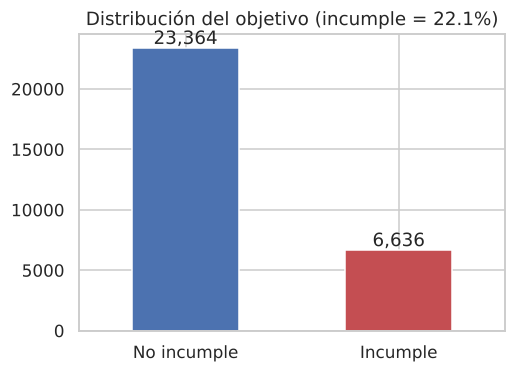

Razón de desbalance ≈ 3.5 : 1


In [6]:
tasa = df["DEFAULT"].mean()
fig, ax = plt.subplots(figsize=(5, 3.5))
df["DEFAULT"].map({0: "No incumple", 1: "Incumple"}).value_counts().plot.bar(ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title(f"Distribución del objetivo (incumple = {tasa:.1%})"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
for p in ax.patches: ax.annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
guardar("01_objetivo"); plt.show()
print(f"Razón de desbalance ≈ {(1-tasa)/tasa:.1f} : 1")

El 22 % de los clientes incumple (≈ 3,5 : 1). Es un **desbalance moderado**: un modelo que siempre prediga "no incumple" tendría 78 % de *accuracy* y 0 % de *recall*, por eso evaluaremos con **Precision, Recall, F1, ROC-AUC y PR-AUC**, y trataremos el desbalance con pesos de clase y ajuste del umbral.

### 2.5 Variables demográficas

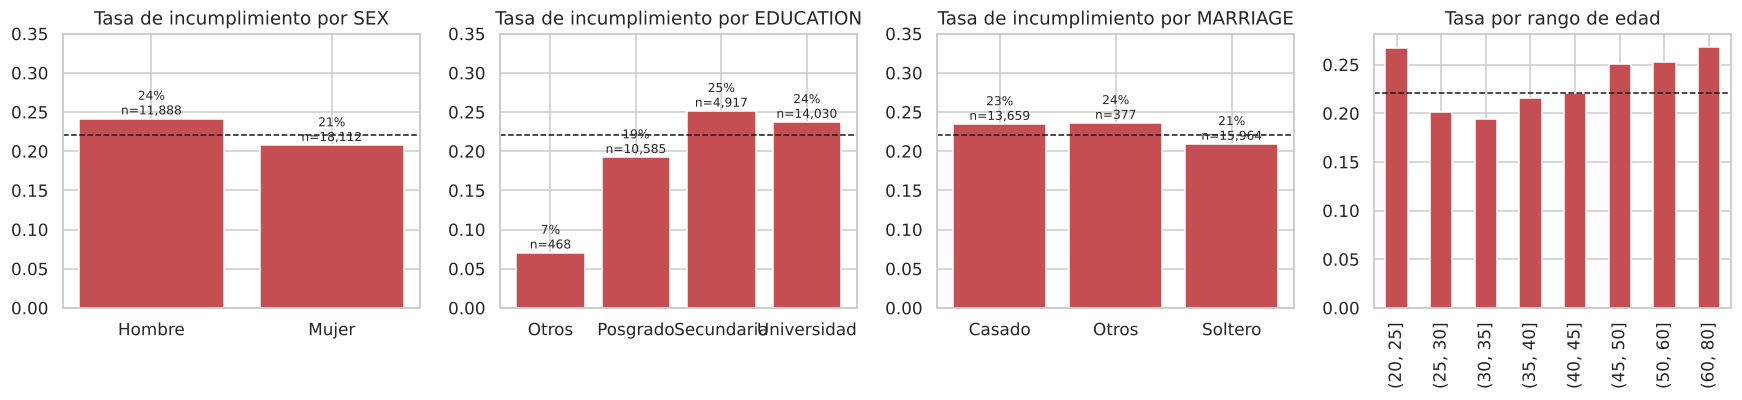

In [7]:
etiquetas = {"SEX": {1: "Hombre", 2: "Mujer"},
             "EDUCATION": {1: "Posgrado", 2: "Universidad", 3: "Secundaria", 4: "Otros"},
             "MARRIAGE": {1: "Casado", 2: "Soltero", 3: "Otros"}}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axes[:3], CAT):
    t = df.groupby(df[c].map(etiquetas[c]))["DEFAULT"].agg(["mean", "size"])
    ax.bar(t.index, t["mean"], color="#C44E52")
    ax.axhline(tasa, ls="--", c="k", lw=1); ax.set_title(f"Tasa de incumplimiento por {c}")
    for i, (m, n) in enumerate(t.values): ax.text(i, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, .35)
edad = pd.cut(df["AGE"], [20, 25, 30, 35, 40, 45, 50, 60, 80])
df.groupby(edad, observed=True)["DEFAULT"].mean().plot.bar(ax=axes[3], color="#C44E52")
axes[3].axhline(tasa, ls="--", c="k", lw=1); axes[3].set_title("Tasa por rango de edad"); axes[3].set_xlabel("")
plt.tight_layout(); guardar("02_demograficas"); plt.show()

Las diferencias demográficas existen pero son **pequeñas**: hombres 24 % vs. mujeres 21 %; secundaria 25 % vs. posgrado 19 %; y los extremos de edad (≤25 y >45 años) ≈ 25–27 % frente a ≈ 19–20 % entre 26 y 35 años. La categoría educativa "otros" tiene solo 7 %, pero agrupa códigos no documentados, así que no conviene sobreinterpretarla. Estas variables son además **sensibles** (sexo, edad, estado civil); volveremos a esto en la discusión de riesgos.

### 2.6 Historial de pagos (`PAY_k`)

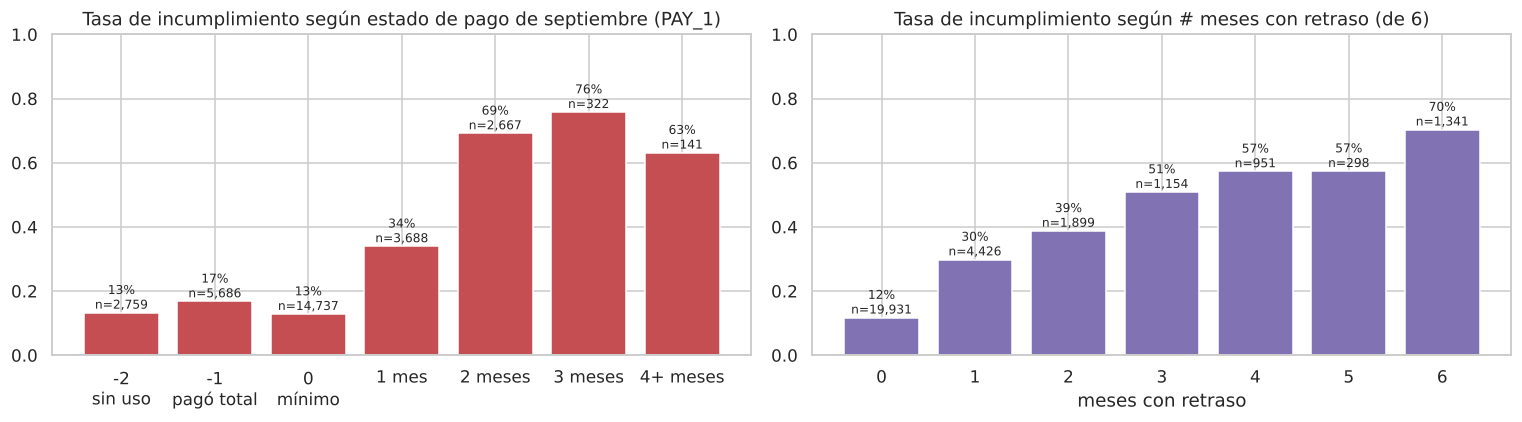

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
t = df.groupby(df["PAY_1"].clip(upper=4))["DEFAULT"].agg(["mean", "size"])
axes[0].bar(t.index.astype(str), t["mean"], color="#C44E52")
for i, (m, n) in enumerate(t.values): axes[0].text(i, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(range(len(t))); axes[0].set_xticklabels(["-2\nsin uso", "-1\npagó total", "0\nmínimo", "1 mes", "2 meses", "3 meses", "4+ meses"])
axes[0].set_title("Tasa de incumplimiento según estado de pago de septiembre (PAY_1)"); axes[0].set_ylim(0, 1)

n_mora = (df[PAY] > 0).sum(axis=1)
t2 = df.groupby(n_mora)["DEFAULT"].agg(["mean", "size"])
axes[1].bar(t2.index, t2["mean"], color="#8172B3")
for i, (m, n) in zip(t2.index, t2.values): axes[1].text(i, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=8)
axes[1].set_title("Tasa de incumplimiento según # meses con retraso (de 6)"); axes[1].set_xlabel("meses con retraso"); axes[1].set_ylim(0, 1)
plt.tight_layout(); guardar("03_historial_pagos"); plt.show()

**Hallazgo clave del EDA:** el historial de pagos es, con diferencia, la señal más fuerte. Quien está al día en septiembre incumple ~13–17 %, quien tiene **2 meses de retraso incumple ~70 %**. La tasa también crece de forma casi monótona con el número de meses en mora. Esta relación es ordinal, por lo que conservaremos `PAY_k` como variables numéricas.

### 2.7 Variables financieras: cupo, facturación y pagos

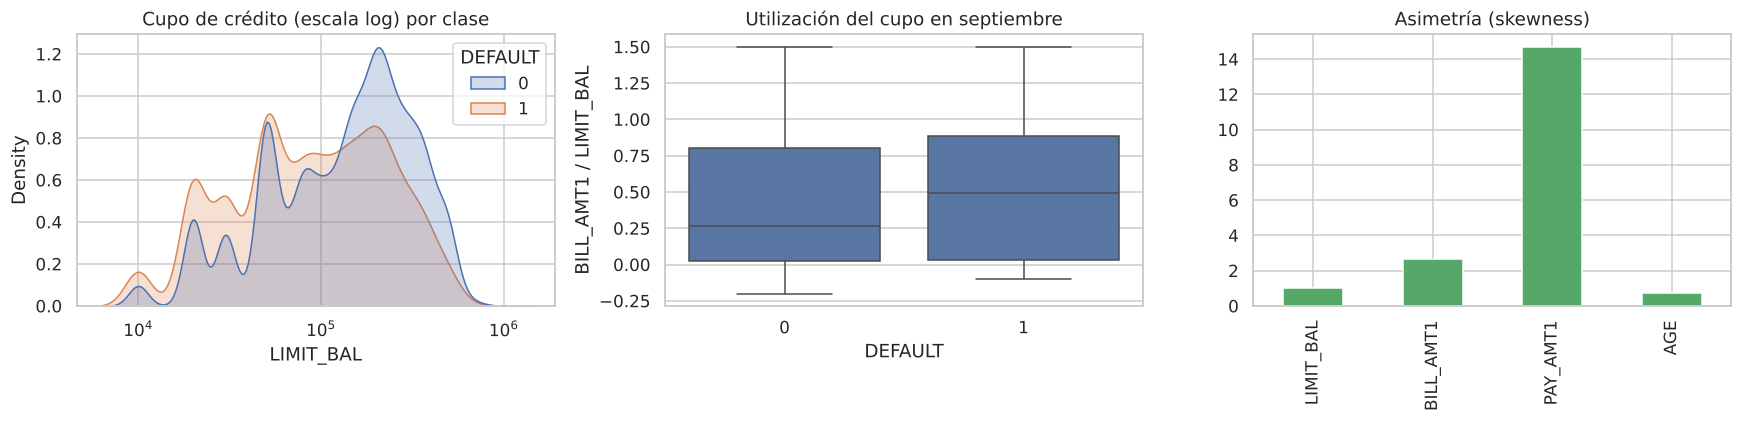

,LIMIT_BAL,BILL_AMT1,BILL_AMT2,PAY_AMT1,PAY_AMT2
atípicos IQR,167,2400,2395,2745,2714


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.kdeplot(data=df, x="LIMIT_BAL", hue="DEFAULT", common_norm=False, fill=True, ax=axes[0], log_scale=True)
axes[0].set_title("Cupo de crédito (escala log) por clase")
sns.boxplot(x=df["DEFAULT"], y=(df["BILL_AMT1"] / df["LIMIT_BAL"]).clip(-0.2, 1.5), ax=axes[1])
axes[1].set_title("Utilización del cupo en septiembre"); axes[1].set_ylabel("BILL_AMT1 / LIMIT_BAL")
cols = ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1", "AGE"]
(df[cols].skew()).plot.bar(ax=axes[2], color="#55A868"); axes[2].set_title("Asimetría (skewness)")
plt.tight_layout(); guardar("04_financieras"); plt.show()

def n_atipicos(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())
pd.Series({c: n_atipicos(df[c]) for c in ["LIMIT_BAL"] + BILL[:2] + PAMT[:2]}, name="atípicos IQR").to_frame().T

- Los clientes que incumplen tienen **cupos más bajos** y **mayor utilización** del cupo.
- Los montos (facturas y pagos) son **muy asimétricos** y con miles de atípicos según el criterio IQR. No son errores: son clientes con cupos altos o pagos grandes. En lugar de eliminarlos aplicaremos una **transformación logarítmica con signo** (`sign(x)·log(1+|x|)`), que reduce su influencia en los modelos lineales y en las distancias del clustering.

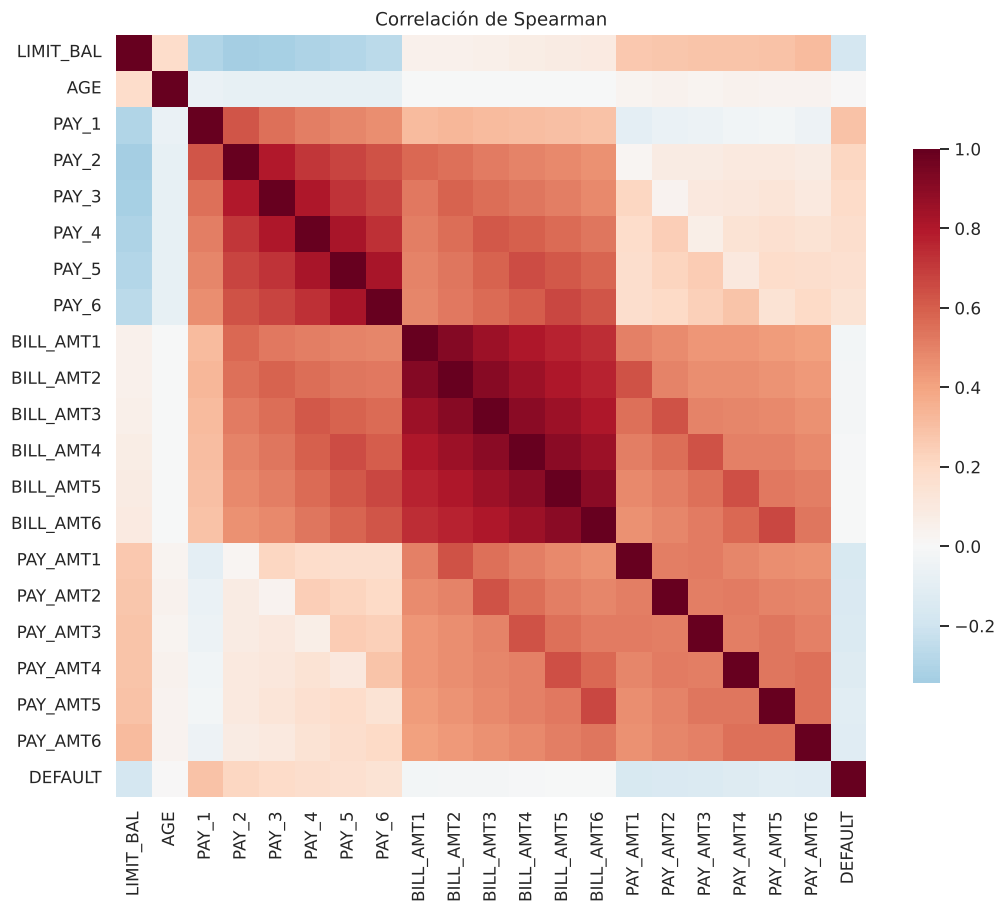

PAY_1        0.292
PAY_2        0.217
PAY_3        0.195
PAY_4        0.174
LIMIT_BAL   -0.170
PAY_AMT1    -0.160
PAY_5        0.159
PAY_AMT2    -0.151
Name: DEFAULT, dtype: float64


In [10]:
fig, ax = plt.subplots(figsize=(11, 9))
corr = df.drop(columns=CAT).corr(method="spearman")
sns.heatmap(corr, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlación de Spearman"); guardar("05_correlacion"); plt.show()
print(corr["DEFAULT"].drop("DEFAULT").sort_values(key=abs, ascending=False).head(8).round(3))

- `BILL_AMT1..6` están **casi perfectamente correlacionadas entre sí** (ρ > 0,9): hay mucha redundancia temporal. Lo mismo ocurre, en menor grado, con `PAY_1..6`.
- Las variables más correlacionadas con `DEFAULT` son los estados de pago, seguidas por el cupo (negativa).
- La multicolinealidad afecta la interpretación de coeficientes de la regresión logística (se usará regularización) pero no a los árboles.

## 3. Preprocesamiento

### 3.1 Ingeniería de características
Se crean variables **calculadas fila a fila** (no aprenden nada del conjunto, así que no hay fuga de información). Resumen el comportamiento de los seis meses en indicadores interpretables:

| Variable | Definición | Intuición |
|---|---|---|
| `n_meses_mora` | # meses con `PAY_k > 0` | persistencia de la mora |
| `max_mora` | máximo de `PAY_k` (mín. 0) | severidad de la mora |
| `meses_inactivo` | # meses con `PAY_k = −2` | tarjeta sin uso |
| `util_media`, `util_max` | `BILL_AMT_k / LIMIT_BAL` | presión sobre el cupo |
| `ratio_pago` | Σ pagos / Σ facturas del mes anterior (acotado a [0, 1]) | qué fracción de la deuda se paga |
| `tendencia_deuda` | (`BILL_AMT1` − `BILL_AMT6`) / `LIMIT_BAL` | la deuda crece o decrece |

In [11]:
def crear_variables(d):
    d = d.copy()
    d["n_meses_mora"]   = (d[PAY] > 0).sum(axis=1)
    d["max_mora"]       = d[PAY].max(axis=1).clip(lower=0)
    d["meses_inactivo"] = (d[PAY] == -2).sum(axis=1)
    util = d[BILL].div(d["LIMIT_BAL"], axis=0)
    d["util_media"] = util.mean(axis=1).clip(-0.5, 2)
    d["util_max"]   = util.max(axis=1).clip(-0.5, 2)
    # PAY_AMT_k paga la factura del mes anterior BILL_AMT_{k+1}
    pagado  = d[PAMT[:5]].sum(axis=1)
    debido  = d[BILL[1:]].clip(lower=0).sum(axis=1)
    d["ratio_pago"] = np.where(debido > 0, pagado / debido.replace(0, np.nan), 1.0)
    d["ratio_pago"] = d["ratio_pago"].clip(0, 1)
    d["tendencia_deuda"] = ((d["BILL_AMT1"] - d["BILL_AMT6"]) / d["LIMIT_BAL"]).clip(-2, 2)
    return d

df = crear_variables(df)
NUEVAS = ["n_meses_mora", "max_mora", "meses_inactivo", "util_media", "util_max", "ratio_pago", "tendencia_deuda"]
df.groupby("DEFAULT")[NUEVAS].mean().T.round(3)

DEFAULT,0,1
n_meses_mora,0.504,1.996
max_mora,0.470,1.428
meses_inactivo,0.851,0.682
util_media,0.351,0.449
util_max,0.474,0.560
ratio_pago,0.408,0.310
tendencia_deuda,0.108,0.091


Las nuevas variables separan bien las clases: quienes incumplen tienen en promedio más meses en mora, mayor utilización y pagan una fracción menor de lo que deben.

### 3.2 Partición entrenamiento / prueba
Se separa **antes de cualquier transformación que aprenda de los datos**: 80 % entrenamiento, 20 % prueba, estratificado para conservar el 22 % de morosos en ambos conjuntos. El conjunto de prueba solo se usa al final.

In [12]:
X = df.drop(columns="DEFAULT")
y = df["DEFAULT"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, f"– tasa de incumplimiento {y_train.mean():.3f}")
print("Prueba:       ", X_test.shape,  f"– tasa de incumplimiento {y_test.mean():.3f}")

Entrenamiento: (24000, 30) – tasa de incumplimiento 0.221
Prueba:        (6000, 30) – tasa de incumplimiento 0.221


### 3.3 Pipeline de transformación (sin fuga de información)
Todo se encapsula en un `Pipeline` de scikit-learn, de modo que el escalador y el codificador **se ajustan solo con los pliegues de entrenamiento** dentro de la validación cruzada y luego se aplican a validación/prueba.

- **Montos** (`LIMIT_BAL`, `BILL_AMT*`, `PAY_AMT*`): log con signo + estandarización.
- **Ordinales y continuas** (`AGE`, `PAY_k`, variables creadas): estandarización.
- **Categóricas** (`SEX`, `EDUCATION`, `MARRIAGE`): *one-hot* (baja cardinalidad: 2–4 niveles), `handle_unknown="ignore"`.

La estandarización es necesaria para la regresión logística (regularización y convergencia); los modelos de árboles no la necesitan pero no los perjudica.

In [13]:
MONTOS = ["LIMIT_BAL"] + BILL + PAMT
OTRAS  = ["AGE"] + PAY + NUEVAS
log_signo = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)), feature_names_out="one-to-one")

preproceso = ColumnTransformer([
    ("montos", Pipeline([("log", log_signo), ("esc", StandardScaler())]), MONTOS),
    ("num",    StandardScaler(), OTRAS),
    ("cat",    OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CAT),
])
FEATS = MONTOS + OTRAS + CAT
X_train, X_test = X_train[FEATS], X_test[FEATS]
print("Variables de entrada:", len(FEATS))

Variables de entrada: 30


## 4. Componente supervisado

### 4.1 Selección y justificación de algoritmos

| Modelo | Por qué es apropiado | Supuestos | Ventajas | Limitaciones en estos datos |
|---|---|---|---|---|
| **Regresión logística** (L2) | Línea base estándar en *credit scoring*; produce probabilidades calibradas e interpretables | Relación lineal entre variables y log-odds; poca multicolinealidad | Interpretable (coeficientes = efecto en el riesgo), rápida, aceptada por reguladores | No captura no linealidades ni interacciones (p. ej. mora × utilización); afectada por la colinealidad de `BILL_AMT` |
| **Random Forest** | Ensamble de árboles que captura no linealidades e interacciones sin supuestos de distribución | Ninguno fuerte sobre la distribución | Robusto a atípicos y colinealidad, poco sobreajuste | Menos interpretable; probabilidades menos calibradas; más costoso |
| **Histogram Gradient Boosting** | *Boosting* secuencial: suele ser el estado del arte en datos tabulares | Ninguno fuerte | Alto desempeño, rápido (binning por histogramas) | Más hiperparámetros, riesgo de sobreajuste, "caja negra" |

**Tratamiento del desbalance:** se usa `class_weight="balanced"` (penaliza más los errores sobre morosos) y, en lugar de usar el umbral 0,5 por defecto, se **elige el umbral que maximiza F1 con predicciones fuera de pliegue (*out-of-fold*) en entrenamiento**. Se descartó SMOTE porque genera clientes sintéticos interpolando historiales de pago discretos (p. ej. `PAY_k = 1,4`), lo que no tiene significado, y con un desbalance de 3,5 : 1 los pesos de clase son suficientes.

**Búsqueda de hiperparámetros:** `RandomizedSearchCV` con validación cruzada estratificada, optimizando **PR-AUC** (*average precision*), la métrica más informativa con clases desbalanceadas.

In [14]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)

modelos = {
    "Regresión logística": (
        LogisticRegression(class_weight="balanced", max_iter=2000),
        {"clf__C": np.logspace(-3, 1, 12)}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        {"clf__max_depth": [6, 8, 10, 14, None], "clf__min_samples_leaf": [5, 10, 20, 40],
         "clf__max_features": ["sqrt", 0.3]}),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
        {"clf__learning_rate": [0.03, 0.05, 0.1], "clf__max_leaf_nodes": [15, 31, 63],
         "clf__min_samples_leaf": [20, 50, 100], "clf__l2_regularization": [0, 1, 5],
         "clf__max_iter": [200, 400]}),
}
N_ITER = {"Regresión logística": 12, "Random Forest": 8, "Gradient Boosting": 10}

busquedas = {}
for nombre, (est, grid) in modelos.items():
    t0 = time.time()
    pipe = Pipeline([("prep", preproceso), ("clf", est)])
    s = RandomizedSearchCV(pipe, grid, n_iter=N_ITER[nombre], scoring="average_precision",
                           cv=cv, random_state=SEED, n_jobs=1, refit=True)
    s.fit(X_train, y_train)
    busquedas[nombre] = s
    print(f"{nombre:20s} PR-AUC CV = {s.best_score_:.4f}  ({time.time()-t0:.0f}s)  {s.best_params_}")

Regresión logística  PR-AUC CV = 0.5096  (4s)  {'clf__C': np.float64(0.005336699231206312)}


Random Forest        PR-AUC CV = 0.5645  (176s)  {'clf__min_samples_leaf': 5, 'clf__max_features': 0.3, 'clf__max_depth': 8}


Gradient Boosting    PR-AUC CV = 0.5641  (52s)  {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 15, 'clf__max_iter': 200, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 5}


### 4.2 Selección del umbral de decisión (sin tocar el conjunto de prueba)
Con las predicciones *out-of-fold* del conjunto de entrenamiento se busca el umbral que maximiza F1. Así la decisión se toma con datos que el modelo no vio, pero sin usar el conjunto de prueba.

In [15]:
umbrales = {}
for nombre, s in busquedas.items():
    oof = cross_val_predict(s.best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    p, r, t = precision_recall_curve(y_train, oof)
    f1 = 2 * p * r / (p + r + 1e-12)
    i = np.nanargmax(f1[:-1])
    umbrales[nombre] = t[i]
    print(f"{nombre:20s} umbral óptimo = {t[i]:.3f}  (F1 OOF = {f1[i]:.3f}, P = {p[i]:.3f}, R = {r[i]:.3f})")

Regresión logística  umbral óptimo = 0.598  (F1 OOF = 0.533, P = 0.502, R = 0.568)


Random Forest        umbral óptimo = 0.540  (F1 OOF = 0.549, P = 0.528, R = 0.571)


Gradient Boosting    umbral óptimo = 0.558  (F1 OOF = 0.549, P = 0.515, R = 0.587)


### 4.3 Evaluación en el conjunto de prueba

In [16]:
def evaluar(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    return {"Precision": precision_score(y_true, pred), "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, prob),
            "PR-AUC": average_precision_score(y_true, prob)}

probs, filas = {}, []
for nombre, s in busquedas.items():
    probs[nombre] = s.predict_proba(X_test)[:, 1]
    filas.append({"Modelo": nombre, "Umbral": "0,5", **evaluar(y_test, probs[nombre], 0.5)})
    filas.append({"Modelo": nombre, "Umbral": f"{umbrales[nombre]:.2f} (óptimo)", **evaluar(y_test, probs[nombre], umbrales[nombre])})
# Línea base trivial
filas.append({"Modelo": "Línea base: regla PAY_1 ≥ 1", "Umbral": "-",
              **evaluar(y_test, (X_test["PAY_1"] >= 1).astype(float), 0.5)})
resultados = pd.DataFrame(filas).set_index(["Modelo", "Umbral"])
resultados.round(3).style.highlight_max(axis=0, color="#d4edda").format("{:.3f}")

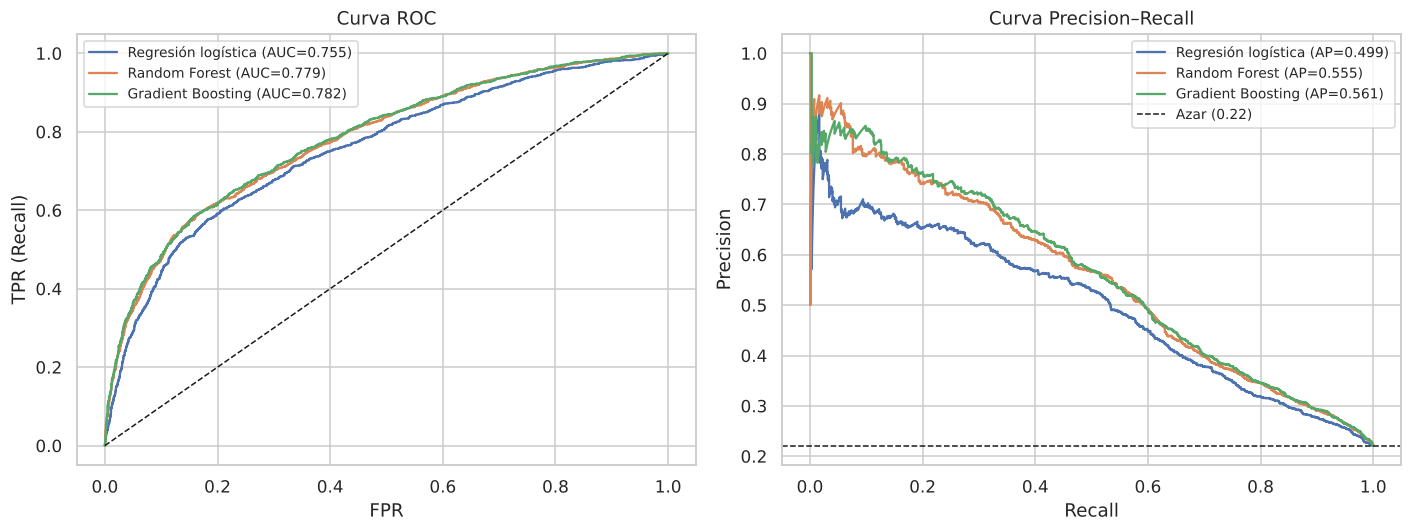

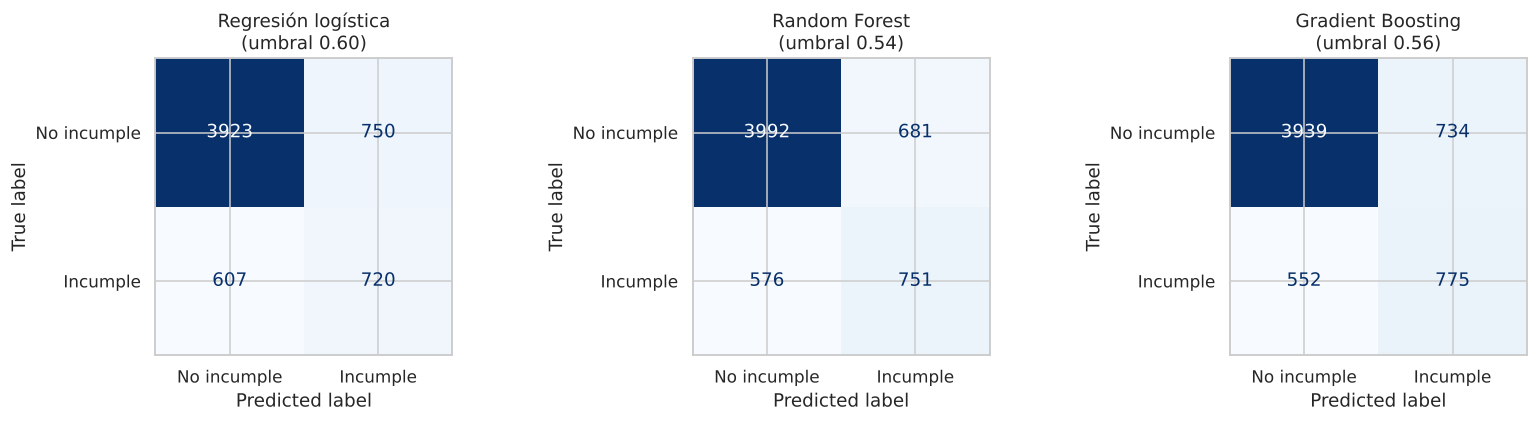

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label=f"{nombre} (AP={average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set(title="Curva ROC", xlabel="FPR", ylabel="TPR (Recall)")
axes[1].axhline(y_test.mean(), c="k", ls="--", lw=1, label=f"Azar ({y_test.mean():.2f})")
axes[1].set(title="Curva Precision–Recall", xlabel="Recall", ylabel="Precision")
for a in axes: a.legend(loc="best", fontsize=9)
plt.tight_layout(); guardar("06_roc_pr"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, p) in zip(axes, probs.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= umbrales[nombre]).astype(int)),
                           display_labels=["No incumple", "Incumple"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{nombre}\n(umbral {umbrales[nombre]:.2f})")
plt.tight_layout(); guardar("07_matrices_confusion"); plt.show()

**Interpretación de los resultados en prueba**
- Los dos ensambles (**Gradient Boosting** y **Random Forest**) superan a la regresión logística en todas las métricas de ranking (ROC-AUC ≈ 0,78 vs. 0,755; PR-AUC ≈ 0,56 vs. 0,50) y claramente a la regla trivial "tiene retraso en septiembre" (PR-AUC 0,36). Las no linealidades e interacciones aportan, pero **la mejora es modesta**: la mayor parte de la señal ya está en el historial de pagos.
- La diferencia entre RF y Gradient Boosting es mínima (≈ 0,005 en PR-AUC), dentro de la variabilidad esperable.
- **Ajustar el umbral** con datos de entrenamiento mueve el balance Precision/Recall: con 0,5 y pesos balanceados los modelos marcan más clientes (Recall ≈ 0,60–0,63 pero Precision ≈ 0,44–0,49); con el umbral optimizado para F1 la precisión sube a ≈ 0,51–0,52. El umbral final debe definirse con el **costo de negocio** de cada error, no solo con F1.
- Con Gradient Boosting se detecta ≈ 58 % de los morosos y aproximadamente uno de cada dos clientes marcados como riesgosos realmente incumple. El techo de desempeño (F1 ≈ 0,55) es conocido en la literatura de este dataset: con seis meses de historial y sin información de ingresos o de buró, una parte del incumplimiento no es predecible.

### 4.4 Importancia de las variables

Mejor modelo por PR-AUC: Gradient Boosting


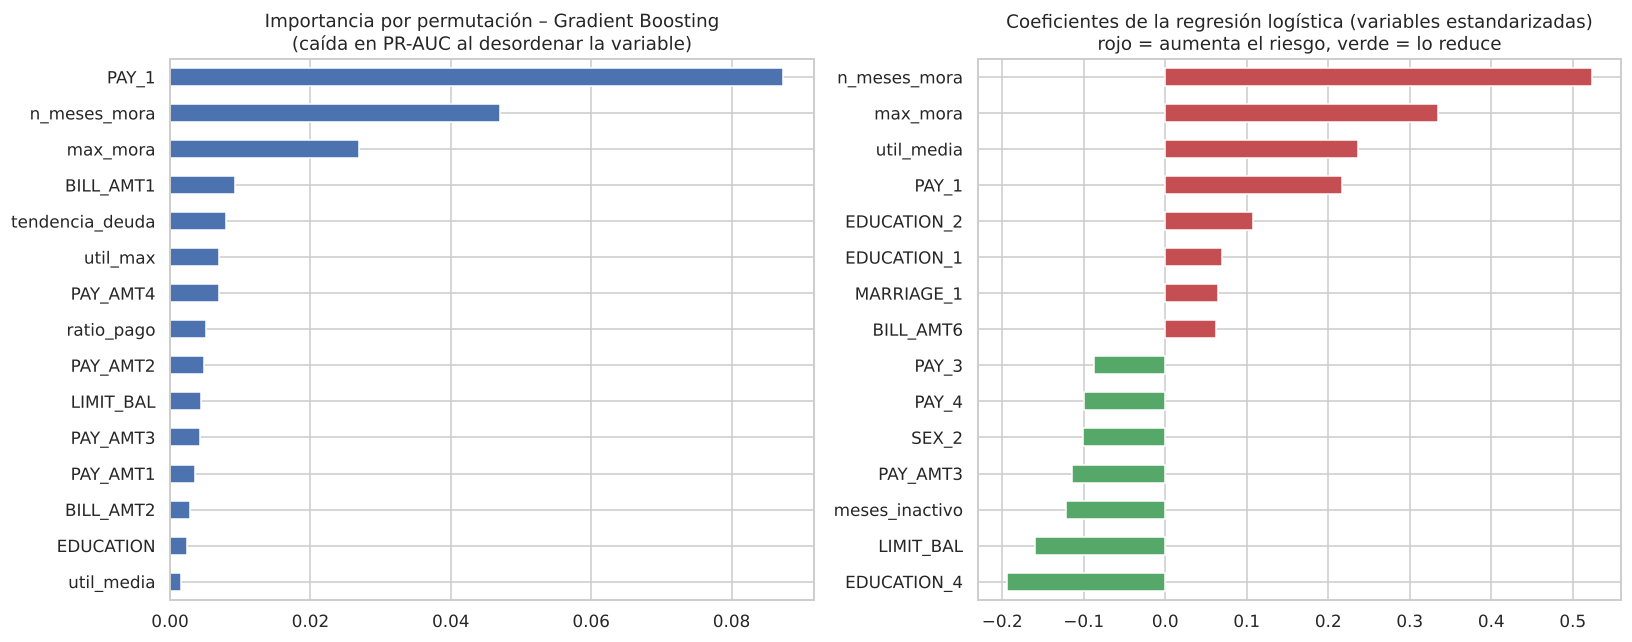

In [18]:
mejor_nombre = resultados.xs("0,5", level="Umbral")["PR-AUC"].idxmax()
mejor = busquedas[mejor_nombre].best_estimator_
print("Mejor modelo por PR-AUC:", mejor_nombre)

perm = permutation_importance(mejor, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

log_model = busquedas["Regresión logística"].best_estimator_
coef = pd.Series(log_model.named_steps["clf"].coef_[0],
                 index=log_model.named_steps["prep"].get_feature_names_out()).sort_values()
coef.index = coef.index.str.replace(r"^\w+__", "", regex=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.tail(15).plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Importancia por permutación – {mejor_nombre}\n(caída en PR-AUC al desordenar la variable)")
extremos = pd.concat([coef.head(7), coef.tail(8)])
extremos.plot.barh(ax=axes[1], color=["#C44E52" if v > 0 else "#55A868" for v in extremos])
axes[1].set_title("Coeficientes de la regresión logística (variables estandarizadas)\nrojo = aumenta el riesgo, verde = lo reduce")
plt.tight_layout(); guardar("08_importancia"); plt.show()

- En ambos modelos dominan las variables de **historial de pagos**: el estado de septiembre (`PAY_1`), el número de meses en mora y la severidad máxima. Le siguen el cupo (`LIMIT_BAL`, menor cupo → más riesgo), la utilización y los montos pagados.
- Algunos coeficientes de la regresión logística tienen signo "contraintuitivo" (`PAY_3`, `PAY_4` negativos). Es efecto de la **multicolinealidad**: su información ya está contenida en `n_meses_mora` y `max_mora`, y el modelo ajusta el efecto marginal. Por eso los coeficientes individuales deben interpretarse con cautela.
- Las variables demográficas tienen importancia muy baja en el modelo de mejor desempeño.

### 4.5 ¿Cuánto aporta cada grupo de variables?
Para responder directamente a *"la capacidad predictiva del historial de pagos y de las variables financieras"*, se entrena el mejor modelo con distintos subconjuntos de variables (validación cruzada en entrenamiento).

In [19]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
grupos = {
    "Solo demográficas": ["AGE"] + CAT,
    "Solo financieras (cupo, facturas, pagos)": MONTOS + ["util_media", "util_max", "ratio_pago", "tendencia_deuda"],
    "Solo historial de pagos (PAY_k y derivadas)": PAY + ["n_meses_mora", "max_mora", "meses_inactivo"],
    "Todas excepto demográficas": [c for c in FEATS if c not in ["AGE"] + CAT],
    "Todas": FEATS,
}
clf_base = clone(mejor.named_steps["clf"])
filas = []
for g, cols in grupos.items():
    num_m = [c for c in cols if c in MONTOS]; num_o = [c for c in cols if c in OTRAS]; cat = [c for c in cols if c in CAT]
    prep = ColumnTransformer([t for t in [
        ("montos", Pipeline([("log", log_signo), ("esc", StandardScaler())]), num_m) if num_m else None,
        ("num", StandardScaler(), num_o) if num_o else None,
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat) if cat else None] if t])
    pipe = Pipeline([("prep", prep), ("clf", clone(clf_base))])
    sc = cross_val_score(pipe, X_train[cols], y_train, cv=cv, scoring="roc_auc")
    ap = cross_val_score(pipe, X_train[cols], y_train, cv=cv, scoring="average_precision")
    filas.append({"Grupo de variables": g, "n": len(cols), "ROC-AUC (CV)": sc.mean(), "PR-AUC (CV)": ap.mean()})
grupos_res = pd.DataFrame(filas).set_index("Grupo de variables")
grupos_res.round(3)

,n,ROC-AUC (CV),PR-AUC (CV)
Grupo de variables,,,
Solo demográficas,4,0.563,0.256
"Solo financieras (cupo, facturas, pagos)",17,0.736,0.461
Solo historial de pagos (PAY_k y derivadas),9,0.750,0.528
Todas excepto demográficas,26,0.785,0.560
Todas,30,0.787,0.564


- **El historial de pagos por sí solo** (9 variables) logra casi todo el desempeño (ROC-AUC ≈ 0,75); las variables financieras solas alcanzan ≈ 0,74, y **combinadas** suben a ≈ 0,785: son complementarias.
- Las variables demográficas solas están cerca del azar (ROC-AUC ≈ 0,56) y **quitarlas prácticamente no cambia el desempeño** (0,785 vs. 0,787). Esto es relevante éticamente: se puede construir un modelo igual de útil **sin usar sexo, edad, estado civil ni educación**.

### 4.6 Riesgos: desempeño por grupo sensible
Un modelo de crédito puede tratar de forma desigual a grupos protegidos. Se revisa, en prueba, si las tasas de error del mejor modelo difieren por sexo y edad.

In [20]:
pred_mejor = (probs[mejor_nombre] >= umbrales[mejor_nombre]).astype(int)
aux = pd.DataFrame({"y": y_test.values, "pred": pred_mejor,
                    "Sexo": X_test["SEX"].map({1: "Hombre", 2: "Mujer"}).values,
                    "Edad": pd.cut(X_test["AGE"], [0, 30, 45, 100], labels=["≤30", "31–45", ">45"]).values})
def metricas_grupo(g):
    tn, fp, fn, tp = confusion_matrix(g["y"], g["pred"], labels=[0, 1]).ravel()
    return pd.Series({"n": len(g), "Tasa real de impago": g["y"].mean(), "Marcados como riesgo": g["pred"].mean(),
                      "Recall (TPR)": tp/(tp+fn), "Falsos positivos (FPR)": fp/(fp+tn), "Precision": tp/max(tp+fp, 1)})
pd.concat({"Sexo": aux.groupby("Sexo").apply(metricas_grupo),
           "Edad": aux.groupby("Edad", observed=True).apply(metricas_grupo)}).round(3)

n  Tasa real de impago  Marcados como riesgo  Recall (TPR)  \
Sexo Hombre  2402.0                0.234                 0.275         0.585   
     Mujer   3598.0                0.213                 0.236         0.584   
Edad ≤30     2181.0                0.220                 0.256         0.608   
     31–45   2853.0                0.212                 0.234         0.556   
     >45      966.0                0.253                 0.294         0.607   

             Falsos positivos (FPR)  Precision  
Sexo Hombre                   0.180      0.497  
     Mujer                    0.142      0.527  
Edad ≤30                      0.157      0.522  
     31–45                    0.147      0.504  
     >45                      0.188      0.521

El *Recall* es similar entre grupos (≈ 0,56–0,61), pero la **tasa de falsos positivos** es mayor para hombres (≈ 18 % vs. 14 % en mujeres) y para mayores de 45 años (≈ 19 %). Parte se explica porque esos grupos tienen mayor tasa real de impago, pero significa que un buen pagador hombre o mayor de 45 tiene más probabilidad de ser rechazado injustamente. En un despliegue real esto debe monitorearse (y, de acuerdo con el punto anterior, se recomienda excluir las variables sensibles).

## 5. Componente no supervisado

### 5.1 Variables para segmentar
El objetivo es agrupar clientes por **comportamiento financiero**, por lo que se usan indicadores de capacidad, uso del cupo y patrón de pago. **`DEFAULT` no se usa** (solo se compara al final) y se excluyen las variables demográficas para que los segmentos describan conducta y no perfiles sociodemográficos.

| Variable | Dimensión |
|---|---|
| `log_limite` | capacidad crediticia |
| `util_media` | uso del cupo |
| `ratio_pago` | disciplina de pago |
| `n_meses_mora`, `max_mora` | persistencia y severidad de la mora |
| `meses_inactivo` | actividad de la tarjeta |
| `tendencia_deuda` | dinámica de endeudamiento |

Se usa el conjunto completo (30.000 clientes): el clustering no tiene etiqueta que filtrar ni un conjunto de prueba que proteger. Para métricas costosas ($O(n^2)$, como Silhouette) se usa una muestra aleatoria estratificada de 6.000 clientes.

In [21]:
seg = pd.DataFrame({
    "log_limite": np.log10(df["LIMIT_BAL"]),
    "util_media": df["util_media"],
    "ratio_pago": df["ratio_pago"],
    "n_meses_mora": df["n_meses_mora"],
    "max_mora": df["max_mora"],
    "meses_inactivo": df["meses_inactivo"],
    "tendencia_deuda": df["tendencia_deuda"],
})
VARS_SEG = seg.columns.tolist()
Z = StandardScaler().fit_transform(seg)
rng = np.random.RandomState(SEED)
idx_m = rng.choice(len(Z), 6000, replace=False)
seg.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_limite,30000.0,5.07,0.41,4.00,4.70,5.15,5.38,6.0
util_media,30000.0,0.37,0.35,-0.23,0.03,0.28,0.69,2.0
ratio_pago,30000.0,0.39,0.41,0.00,0.05,0.12,0.94,1.0
n_meses_mora,30000.0,0.83,1.55,0.00,0.00,0.00,1.00,6.0
max_mora,30000.0,0.68,1.07,0.00,0.00,0.00,2.00,8.0
meses_inactivo,30000.0,0.81,1.79,0.00,0.00,0.00,0.00,6.0
tendencia_deuda,30000.0,0.10,0.30,-1.83,-0.03,0.01,0.18,2.0


### 5.2 Selección y justificación de algoritmos

| Algoritmo | Por qué | Supuestos | Ventajas | Limitaciones |
|---|---|---|---|---|
| **K-Means** | Referencia en segmentación de clientes; centroides = "cliente típico" fácil de comunicar | Grupos esféricos, de tamaño y varianza similares; distancia euclidiana | Escalable a 30.000 registros, simple, interpretable | Sensible a escala y atípicos; fuerza particiones duras; requiere fijar *k* |
| **Mezcla de Gaussianas (GMM)** | Modelo probabilístico: permite grupos elípticos de distinto tamaño y asignación "blanda" | Datos generados por mezcla de normales multivariadas | Más flexible que K-Means; criterio BIC para elegir *k*; probabilidad de pertenencia | Las variables de conteo (meses en mora) no son gaussianas; puede ser inestable |
| **Aglomerativo (Ward)** *(comparación adicional)* | Jerárquico, no depende de una inicialización aleatoria | Ward minimiza varianza intra-grupo (similar a K-Means) | Dendrograma permite ver la estructura a varias escalas | Costo $O(n^2)$ en memoria → se usa sobre la muestra de 6.000 |

### 5.3 Elección del número de grupos

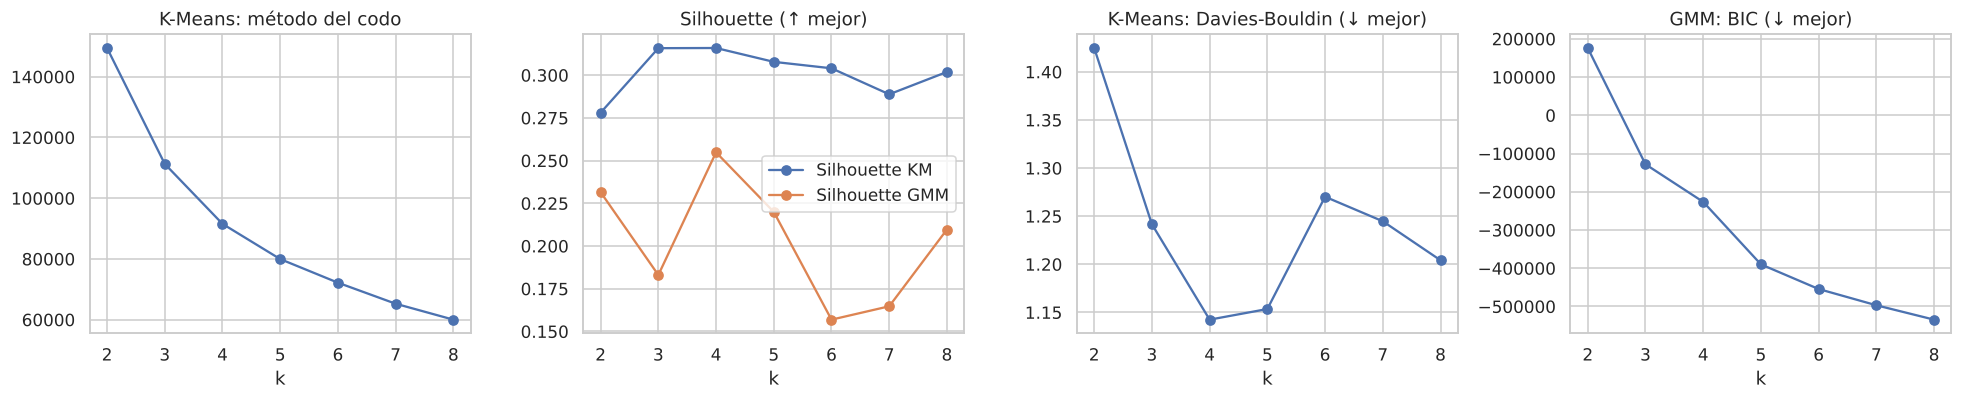

,Inercia,Silhouette KM,DB KM,BIC GMM,Silhouette GMM
k,,,,,
2,149469.336,0.278,1.425,176080.886,0.232
3,111298.233,0.316,1.242,-128109.911,0.183
4,91553.988,0.316,1.142,-226408.053,0.255
5,79957.508,0.308,1.154,-389858.469,0.220
6,72183.752,0.304,1.270,-454353.601,0.157
7,65257.085,0.289,1.245,-496839.922,0.165
8,60011.634,0.302,1.204,-534463.139,0.210


In [22]:
ks = range(2, 9)
filas = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=2, random_state=SEED).fit(Z)
    lg = gm.predict(Z)
    filas.append({"k": k, "Inercia": km.inertia_,
                  "Silhouette KM": silhouette_score(Z[idx_m], km.labels_[idx_m]),
                  "DB KM": davies_bouldin_score(Z, km.labels_),
                  "BIC GMM": gm.bic(Z),
                  "Silhouette GMM": silhouette_score(Z[idx_m], lg[idx_m]) if len(set(lg[idx_m])) > 1 else np.nan})
sel_k = pd.DataFrame(filas).set_index("k")

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
sel_k["Inercia"].plot(ax=axes[0], marker="o", title="K-Means: método del codo")
sel_k[["Silhouette KM", "Silhouette GMM"]].plot(ax=axes[1], marker="o", title="Silhouette (↑ mejor)")
sel_k["DB KM"].plot(ax=axes[2], marker="o", title="K-Means: Davies-Bouldin (↓ mejor)")
sel_k["BIC GMM"].plot(ax=axes[3], marker="o", title="GMM: BIC (↓ mejor)")
plt.tight_layout(); guardar("09_seleccion_k"); plt.show()
sel_k.round(3)

**Criterio de selección.** Se elige **k = 4**:
- El Silhouette de K-Means alcanza su máximo en k = 3–4 (≈ 0,32) y el de GMM es máximo en k = 4 (≈ 0,26).
- Davies-Bouldin es mínimo en k = 4 (≈ 1,14).
- La curva de inercia muestra el codo entre 3 y 4.
- El BIC del GMM sigue bajando con más componentes (con 30.000 datos cada componente extra mejora la verosimilitud), por lo que no es útil como único criterio.
- Con k = 4 los grupos son **interpretables para el negocio**; con k = 2 solo se separa "en mora vs. al día".

Se usa el mismo *k* en los tres algoritmos para compararlos en igualdad de condiciones.

In [23]:
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
gm = GaussianMixture(n_components=K, covariance_type="full", n_init=5, random_state=SEED).fit(Z)
ag = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z[idx_m])
etiq = {"K-Means": km.labels_, "GMM": gm.predict(Z)}

filas = []
for nombre, lab in etiq.items():
    filas.append({"Algoritmo": nombre, "Silhouette (muestra)": silhouette_score(Z[idx_m], lab[idx_m]),
                  "Davies-Bouldin": davies_bouldin_score(Z, lab), "Calinski-Harabasz": calinski_harabasz_score(Z, lab),
                  "Tamaño grupos": sorted(np.bincount(lab).tolist(), reverse=True)})
filas.append({"Algoritmo": "Aglomerativo Ward (muestra)", "Silhouette (muestra)": silhouette_score(Z[idx_m], ag.labels_),
              "Davies-Bouldin": davies_bouldin_score(Z[idx_m], ag.labels_),
              "Calinski-Harabasz": calinski_harabasz_score(Z[idx_m], ag.labels_),
              "Tamaño grupos": sorted(np.bincount(ag.labels_).tolist(), reverse=True)})
met_cluster = pd.DataFrame(filas).set_index("Algoritmo")
met_cluster.round(3)

,Silhouette (muestra),Davies-Bouldin,Calinski-Harabasz,Tamaño grupos
Algoritmo,,,,
K-Means,0.316,1.143,12935.598,"[9792, 9623, 6669, 3916]"
GMM,0.255,1.850,8159.178,"[14480, 6703, 6156, 2661]"
Aglomerativo Ward (muestra),0.272,1.164,2070.584,"[2867, 1463, 1080, 590]"


### 5.4 Estabilidad de los grupos
Un segmento útil debe ser **reproducible**. Se mide con el *Adjusted Rand Index* (ARI; 1 = particiones idénticas, 0 = coincidencia al azar):
- entre corridas de K-Means con distintas semillas,
- entre K-Means entrenado sobre submuestras *bootstrap* y el modelo completo,
- entre algoritmos.

In [24]:
ari_semillas = [adjusted_rand_score(km.labels_, KMeans(K, n_init=1, random_state=s).fit(Z).labels_) for s in range(10)]
ari_boot = []
for b in range(10):
    ib = rng.choice(len(Z), len(Z), replace=True)
    ari_boot.append(adjusted_rand_score(km.labels_, KMeans(K, n_init=10, random_state=b).fit(Z[ib]).predict(Z)))
ari_gmm_semillas = [adjusted_rand_score(etiq["GMM"], GaussianMixture(K, n_init=1, random_state=s).fit(Z).predict(Z)) for s in range(5)]
print(f"K-Means – ARI entre semillas:   {np.mean(ari_semillas):.3f} ± {np.std(ari_semillas):.3f}")
print(f"K-Means – ARI bootstrap:        {np.mean(ari_boot):.3f} ± {np.std(ari_boot):.3f}")
print(f"GMM     – ARI entre semillas:   {np.mean(ari_gmm_semillas):.3f} ± {np.std(ari_gmm_semillas):.3f}")
print(f"ARI K-Means vs GMM:             {adjusted_rand_score(etiq['K-Means'], etiq['GMM']):.3f}")
print(f"ARI K-Means vs Aglomerativo:    {adjusted_rand_score(km.labels_[idx_m], ag.labels_):.3f}  (sobre la muestra)")

K-Means – ARI entre semillas:   0.886 ± 0.213
K-Means – ARI bootstrap:        0.972 ± 0.016
GMM     – ARI entre semillas:   0.944 ± 0.111
ARI K-Means vs GMM:             0.468
ARI K-Means vs Aglomerativo:    0.531  (sobre la muestra)


- **K-Means** obtiene las mejores métricas internas (Silhouette ≈ 0,32, Davies-Bouldin ≈ 1,14, Calinski-Harabasz más alto). El Silhouette ≈ 0,3 indica **estructura moderada**: los clientes forman un continuo más que grupos totalmente separados, lo cual es típico en datos de comportamiento.
- K-Means es **muy estable**: con *bootstrap* el ARI promedio es ≈ 0,97. Con una sola inicialización algunas semillas caen en mínimos locales (ARI ≈ 0,89 ± 0,21), por eso se usa `n_init=20`.
- **GMM** tiene métricas internas peores (las métricas basadas en distancia favorecen grupos esféricos como los de K-Means) y produce una partición distinta (ARI ≈ 0,47 con K-Means): agrupa a revolventes y pagadores al día en un solo componente grande y separa un grupo de clientes con mora intermitente.
- El jerárquico de Ward coincide parcialmente con K-Means (ARI ≈ 0,53), lo cual confirma que los grandes perfiles existen, aunque sus fronteras dependen del algoritmo.

### 5.5 Perfiles de los segmentos (K-Means)
Se describe cada grupo con la media de sus variables originales (no estandarizadas) y un mapa de calor de las medias estandarizadas (cuántas desviaciones estándar se aleja cada grupo del promedio).

In [25]:
df["cluster"] = km.labels_
perfil = df.groupby("cluster").agg(
    n=("LIMIT_BAL", "size"), cupo_medio=("LIMIT_BAL", "median"), util_media=("util_media", "mean"),
    ratio_pago=("ratio_pago", "mean"), n_meses_mora=("n_meses_mora", "mean"), max_mora=("max_mora", "mean"),
    meses_inactivo=("meses_inactivo", "mean"), tendencia_deuda=("tendencia_deuda", "mean"), edad=("AGE", "mean"))
perfil["% clientes"] = perfil["n"] / len(df)
perfil = perfil.sort_values("n_meses_mora")
# Nombres de segmento asignados según el perfil (se calculan con reglas sobre los centroides)
def nombrar(r):
    if r["n_meses_mora"] >= 2:                         return "Morosos persistentes"
    if r["meses_inactivo"] >= 2:                       return "Inactivos / bajo uso"
    if r["util_media"] >= 0.5 and r["ratio_pago"] < .3: return "Revolventes endeudados"
    return "Totaleros / pagadores al día"
perfil["segmento"] = perfil.apply(nombrar, axis=1)
# Garantiza nombres únicos si dos grupos caen en la misma regla
perfil["segmento"] = perfil["segmento"] + perfil.groupby("segmento").cumcount().map(lambda i: "" if i == 0 else f" ({i+1})")
NOMBRES = perfil["segmento"].to_dict()
df["segmento"] = df["cluster"].map(NOMBRES)
perfil.set_index("segmento").round(3)

,n,cupo_medio,util_media,ratio_pago,n_meses_mora,max_mora,meses_inactivo,tendencia_deuda,edad,% clientes
segmento,,,,,,,,,,
Revolventes endeudados,9792,90000.0,0.632,0.090,0.049,0.087,0.117,0.301,35.299,0.326
Totaleros / pagadores al día,9623,210000.0,0.089,0.649,0.254,0.334,0.288,-0.017,35.605,0.321
Inactivos / bajo uso,3916,210000.0,0.023,0.981,0.274,0.276,5.135,0.028,36.807,0.131
Morosos persistentes,6669,60000.0,0.607,0.095,3.154,2.297,0.058,0.037,34.811,0.222


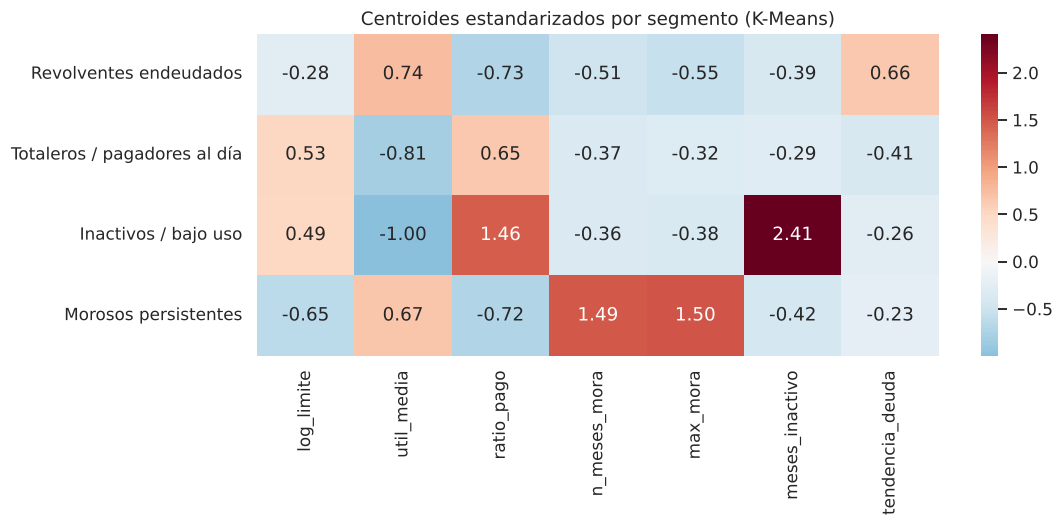

In [26]:
zc = pd.DataFrame(Z, columns=VARS_SEG).groupby(df["segmento"].values).mean().loc[perfil["segmento"]]
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(zc, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Centroides estandarizados por segmento (K-Means)"); ax.set_ylabel("")
guardar("10_perfiles_heatmap"); plt.show()

### 5.6 Contraste con el incumplimiento real (después del agrupamiento)
Solo ahora se usa la etiqueta, **para interpretar** los grupos.

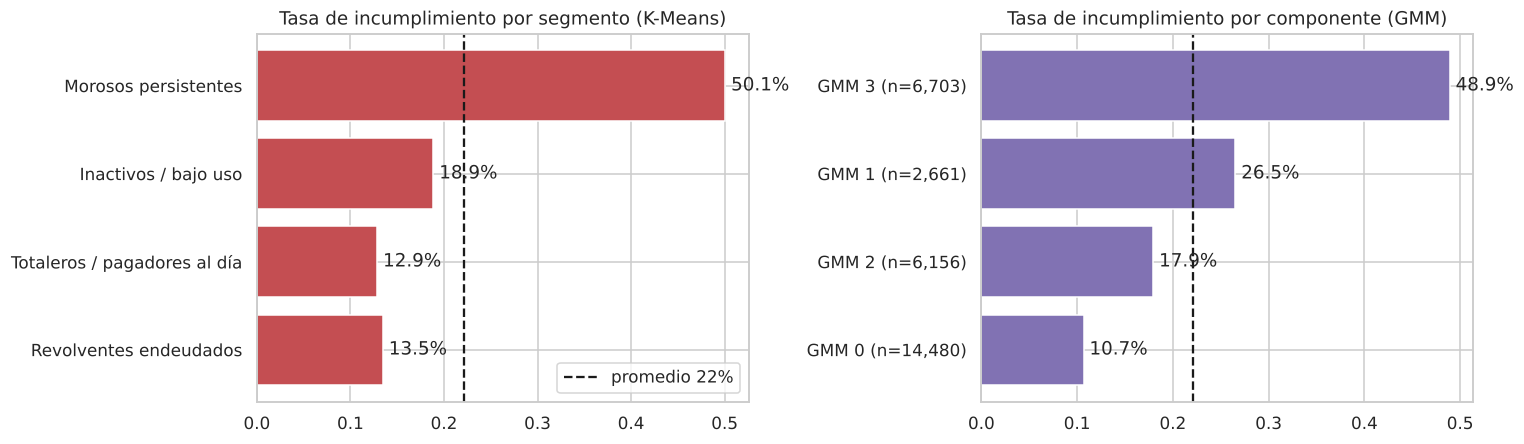

Tabla de contingencia K-Means × DEFAULT


DEFAULT,0,1,All
segmento,,,
Revolventes endeudados,8472,1320,9792
Totaleros / pagadores al día,8385,1238,9623
Inactivos / bajo uso,3177,739,3916
Morosos persistentes,3330,3339,6669
All,23364,6636,30000


K-Means   ARI vs DEFAULT = 0.060   NMI = 0.063
GMM       ARI vs DEFAULT = 0.108   NMI = 0.070

Composición K-Means × GMM (filas = K-Means)


seg_gmm,0,1,2,3
segmento,,,,
Revolventes endeudados,9212,219,0,361
Totaleros / pagadores al día,5265,1401,2752,205
Inactivos / bajo uso,0,514,3402,0
Morosos persistentes,3,527,2,6137


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
orden = perfil["segmento"].tolist()
t = df.groupby("segmento")["DEFAULT"].mean().loc[orden]
axes[0].barh(t.index, t.values, color="#C44E52"); axes[0].axvline(tasa, ls="--", c="k", label=f"promedio {tasa:.0%}")
for i, v in enumerate(t.values): axes[0].text(v, i, f" {v:.1%}", va="center")
axes[0].set_title("Tasa de incumplimiento por segmento (K-Means)"); axes[0].legend()

df["seg_gmm"] = etiq["GMM"]
t_g = df.groupby("seg_gmm")["DEFAULT"].agg(["mean", "size"]).sort_values("mean")
axes[1].barh([f"GMM {i} (n={n:,})" for i, n in zip(t_g.index, t_g["size"])], t_g["mean"], color="#8172B3")
axes[1].axvline(tasa, ls="--", c="k")
for i, v in enumerate(t_g["mean"]): axes[1].text(v, i, f" {v:.1%}", va="center")
axes[1].set_title("Tasa de incumplimiento por componente (GMM)")
plt.tight_layout(); guardar("11_incumplimiento_segmentos"); plt.show()

print("Tabla de contingencia K-Means × DEFAULT")
display(pd.crosstab(df["segmento"], df["DEFAULT"], margins=True).loc[orden + ["All"]])
for nombre, lab in etiq.items():
    print(f"{nombre:8s}  ARI vs DEFAULT = {adjusted_rand_score(y, lab):.3f}   NMI = {normalized_mutual_info_score(y, lab):.3f}")
print("\nComposición K-Means × GMM (filas = K-Means)")
display(pd.crosstab(df["segmento"], df["seg_gmm"]).loc[orden])

**Lectura de los segmentos (K-Means, k = 4)**

| Segmento | % clientes | Perfil | Impago real |
|---|---|---|---|
| **Morosos persistentes** | 22 % | Cupo bajo (mediana 60.000), utilización alta (≈ 61 %), ≈ 3 de 6 meses en mora, pagan ≈ 10 % de lo facturado | **50 %** (2,3× el promedio) |
| **Revolventes endeudados** | 33 % | Cupo medio-bajo (90.000), utilización alta (≈ 63 %), pagan el mínimo (ratio ≈ 0,09) pero **casi nunca se atrasan**; deuda creciente | 13,5 % |
| **Totaleros / pagadores al día** | 32 % | Cupo alto (210.000), utilización baja (≈ 9 %), pagan ≈ 65 % de lo facturado | 12,9 % |
| **Inactivos / bajo uso** | 13 % | Cupo alto, ≈ 5 de 6 meses sin consumo | 18,9 % |

**Hallazgos no evidentes a primera vista:**
1. Una utilización alta del cupo **no implica riesgo por sí sola**: los revolventes usan tanto cupo como los morosos, pero mientras paguen el mínimo a tiempo su impago (13,5 %) es similar al de los totaleros. La diferencia la marca el **atraso**, no el endeudamiento.
2. Los **inactivos** incumplen más que los clientes activos al día (18,9 % vs. 13 %). Con pocos movimientos hay poca información y una reactivación repentina de la tarjeta puede ser señal de dificultad financiera.
3. El GMM aísla un grupo pequeño (≈ 9 %) con **mora intermitente** e impago de 26,5 %, que K-Means reparte entre otros segmentos: un perfil de "riesgo emergente" útil para alertas tempranas.

El ARI/NMI frente a `DEFAULT` es bajo **y eso es esperable**: los segmentos tienen 4 grupos y la etiqueta 2, y los clusters no buscan reproducir la etiqueta sino describir conductas. Lo relevante es que **las tasas de incumplimiento difieren mucho entre segmentos**, es decir, la segmentación sin etiquetas captura una dimensión de riesgo.

## 6. Visualización y reducción de dimensionalidad
- **PCA** (lineal): conserva distancias globales y permite cuantificar la varianza retenida.
- **t-SNE** (no lineal): conserva vecindarios locales; útil para ver grupos, pero las distancias entre grupos y los tamaños **no son interpretables**. Se aplica sobre una muestra de 4.000 clientes por su costo computacional.

Varianza explicada por componente: [0.402 0.229 0.129 0.107 0.075 0.033 0.025]
PC1+PC2 = 63.2%   |   3 componentes = 76.1%


,PC1,PC2
log_limite,0.35,0.01
util_media,-0.47,-0.27
ratio_pago,0.48,0.28
n_meses_mora,-0.37,0.54
max_mora,-0.37,0.54
meses_inactivo,0.37,0.23
tendencia_deuda,-0.11,-0.45


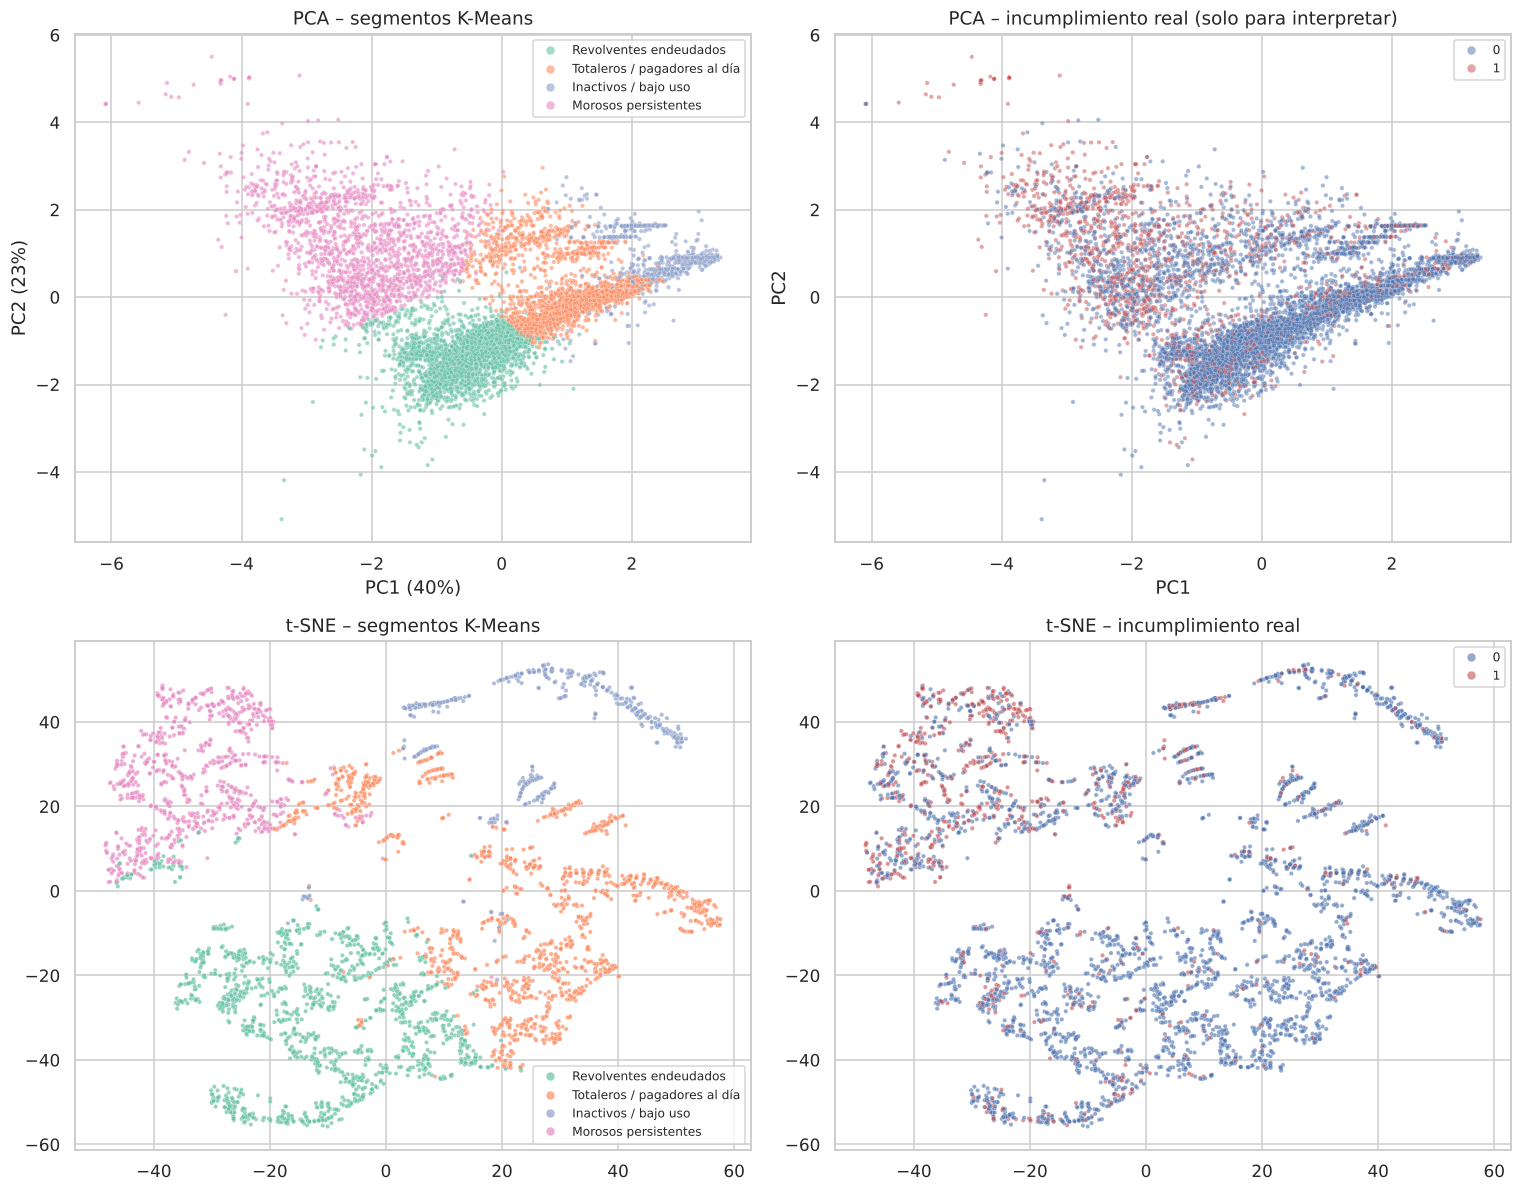

In [28]:
pca = PCA().fit(Z)
P = pca.transform(Z)[:, :2]
var = pca.explained_variance_ratio_
print("Varianza explicada por componente:", np.round(var, 3))
print(f"PC1+PC2 = {var[:2].sum():.1%}   |   3 componentes = {var[:3].sum():.1%}")
cargas = pd.DataFrame(pca.components_[:2].T, index=VARS_SEG, columns=["PC1", "PC2"]).round(2)
display(cargas)

idx_t = rng.choice(len(Z), 4000, replace=False)
T = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(Z[idx_t])

pal = dict(zip(orden, sns.color_palette("Set2", len(orden))))
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
sub = rng.choice(len(Z), 8000, replace=False)
sns.scatterplot(x=P[sub, 0], y=P[sub, 1], hue=df["segmento"].values[sub], hue_order=orden, palette=pal, s=8, alpha=.6, ax=axes[0, 0])
axes[0, 0].set_title("PCA – segmentos K-Means"); axes[0, 0].set(xlabel=f"PC1 ({var[0]:.0%})", ylabel=f"PC2 ({var[1]:.0%})")
sns.scatterplot(x=P[sub, 0], y=P[sub, 1], hue=y.values[sub], palette={0: "#4C72B0", 1: "#C44E52"}, s=8, alpha=.5, ax=axes[0, 1])
axes[0, 1].set_title("PCA – incumplimiento real (solo para interpretar)"); axes[0, 1].set(xlabel="PC1", ylabel="PC2")
sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=df["segmento"].values[idx_t], hue_order=orden, palette=pal, s=8, alpha=.7, ax=axes[1, 0])
axes[1, 0].set_title("t-SNE – segmentos K-Means")
sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=y.values[idx_t], palette={0: "#4C72B0", 1: "#C44E52"}, s=8, alpha=.6, ax=axes[1, 1])
axes[1, 1].set_title("t-SNE – incumplimiento real")
for a in axes.ravel(): a.legend(fontsize=8, markerscale=2)
plt.tight_layout(); guardar("12_pca_tsne"); plt.show()

### 6.1 Proyección PCA de las probabilidades del modelo supervisado

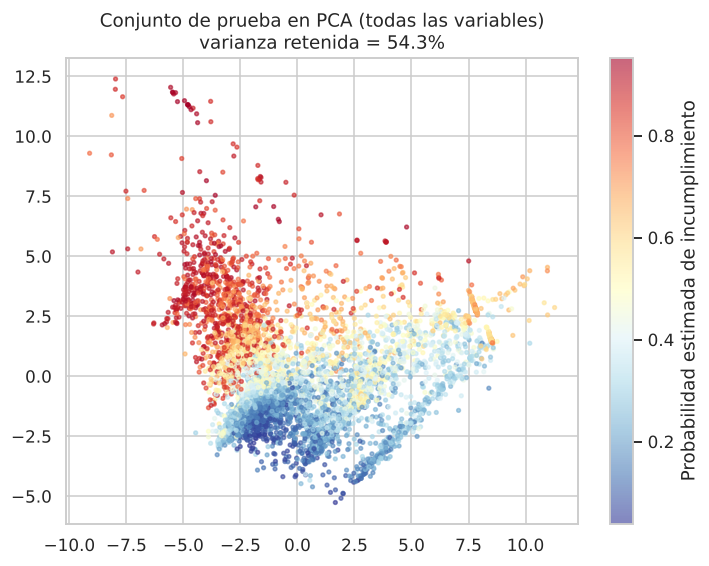

In [29]:
Zt = mejor.named_steps["prep"].transform(X_test)
pca_s = PCA(n_components=2).fit(mejor.named_steps["prep"].transform(X_train))
Pt = pca_s.transform(Zt)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sc = ax.scatter(Pt[:, 0], Pt[:, 1], c=probs[mejor_nombre], cmap="RdYlBu_r", s=6, alpha=.6)
plt.colorbar(sc, label="Probabilidad estimada de incumplimiento")
ax.set_title(f"Conjunto de prueba en PCA (todas las variables)\nvarianza retenida = {pca_s.explained_variance_ratio_.sum():.1%}")
guardar("13_pca_probabilidades"); plt.show()